Brianna Lannerd <br>
10/11/2026 <br>
Lab 07 - Python Physics Engine Prototype <br>
Disclaimer: Parts of this code was taken from the notes and modules and AI was used to debug, fix errors, and occationally give structure for some of this assignment. AI was also used for some graphs as well as code from my previous labs.

In [15]:
#Fixes import path for the engine module
import os
os.chdir(r"C:\Users\blann\Downloads\PHYS311\phys311\labs\lab07")

#Import Required Libraries
import numpy as np
import matplotlib.pyplot as plt

from lab07_engine.engine import (
    Body, Gravity, Drag, Spring, NewtonGravity,
    EulerCromer, VelocityVerlet, World
)

Part A: Section 4 — Class Diagram

```text
                       World
                         |
          +--------------+---------------+
          |              |               |
         Body          Forces        Integrator
          |              |               |
     Position          Gravity       EulerCromer
     Velocity          Drag          VelocityVerlet
     Mass              Spring
     Force             NewtonGravity

                       World
                         |
                    Recorded History
```

 Part B — Validate three earlier labs 

Section 1: Projectile motion (Labs 1–2)

Use gravity only and compare the engine's trajectory to the known constant-acceleration equations. Total energy should remain nearly constant because there is no drag.

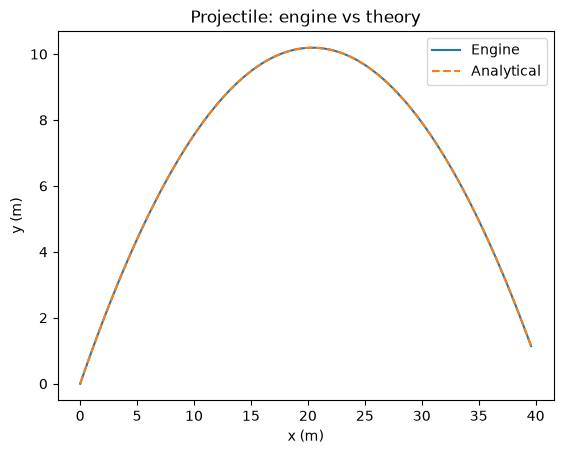

Largest height difference (m): 2.5779378631796135e-13
Maximum energy change (J): 3.694822225952521e-13


In [16]:
v0 = 20.0
angle = np.radians(45)
g = 9.81
w = World(VelocityVerlet())
w.add_body(Body(1, [0, 0], [v0*np.cos(angle), v0*np.sin(angle)]))
w.add_force(Gravity(g))
w.record('time', lambda W: W.time)
w.record('x', lambda W: W.bodies[0].r[0])
w.record('y', lambda W: W.bodies[0].r[1])
w.record('energy', lambda W: W.total_energy())
h = w.run(0.01, 2.8)
t = h['time']
x_theory = v0*np.cos(angle)*t
y_theory = v0*np.sin(angle)*t - 0.5*g*t**2
mask = y_theory >= 0
plt.plot(h['x'][mask], h['y'][mask], label='Engine')
plt.plot(x_theory[mask], y_theory[mask], '--', label='Analytical')
plt.xlabel('x (m)'); plt.ylabel('y (m)'); plt.title('Projectile: engine vs theory')
plt.legend(); plt.show()
print('Largest height difference (m):', np.max(np.abs(h['y']-y_theory)))
print('Maximum energy change (J):', np.max(np.abs(h['energy']-h['energy'][0])))


Confirmation Requested: The simulated trajectory overlaps the curve given by the analytical solution. Mechanical energy ( which is kinetic plus gravitational potential) should remain nearly constant. As shown by the very minimal differences in energy change and height differences, it matches the original results.

Part B: Section 2- Spring oscillator (Lab 3)

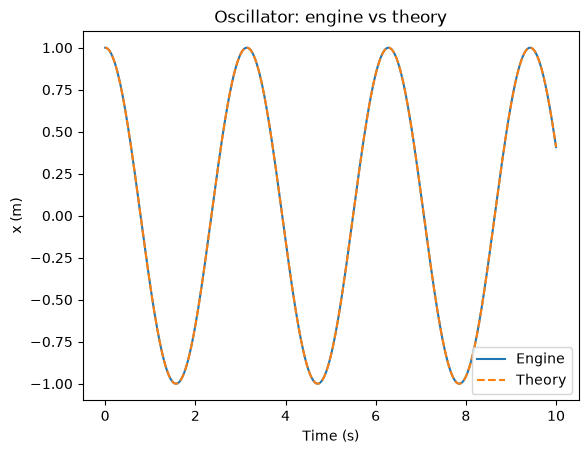

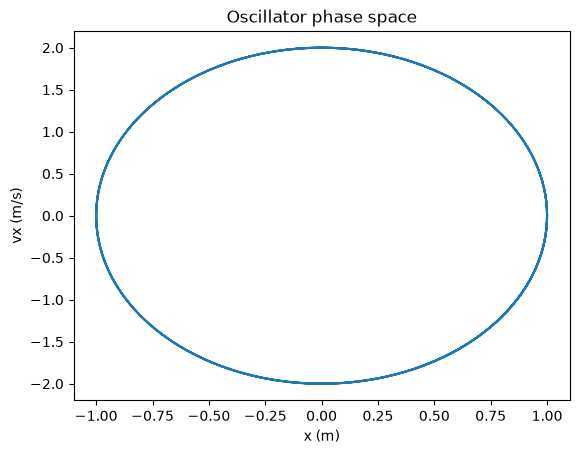

Largest displacement difference (m): 0.0003043514465068675
Maximum energy change (J): 0.000199999532787265


In [17]:
m = 1.0
k = 4.0
w = World(VelocityVerlet())
w.add_body(Body(m, [0, 0], [0, 0], fixed=True))
w.add_body(Body(m, [1, 0], [0, 0]))
w.add_force(Spring(0, 1, k=k, L0=0))
w.record('time', lambda W: W.time)
w.record('x', lambda W: W.bodies[1].r[0])
w.record('vx', lambda W: W.bodies[1].v[0])
w.record('energy', lambda W: W.total_energy())
h = w.run(0.01, 10)
x_theory = np.cos(np.sqrt(k/m)*h['time'])
plt.plot(h['time'], h['x'], label='Engine')
plt.plot(h['time'], x_theory, '--', label='Theory')
plt.xlabel('Time (s)'); plt.ylabel('x (m)'); plt.title('Oscillator: engine vs theory')
plt.legend(); plt.show()
plt.plot(h['x'], h['vx'])
plt.xlabel('x (m)'); plt.ylabel('vx (m/s)'); plt.title('Oscillator phase space')
plt.show()
print('Largest displacement difference (m):', np.max(np.abs(h['x']-x_theory)))
print('Maximum energy change (J):', np.max(np.abs(h['energy']-h['energy'][0])))


Confirmation Requested: The engine follows the cosine solution pretty well and produces the expected elliptical phase-space curve. The oscillating spring exchanges kinetic and potential energy while total energy stays nearly constant. This constantness can be confirmed by the very smaal max energy change and displacement difference. 

Part B: Section 3- Circular orbit (Lab 5)

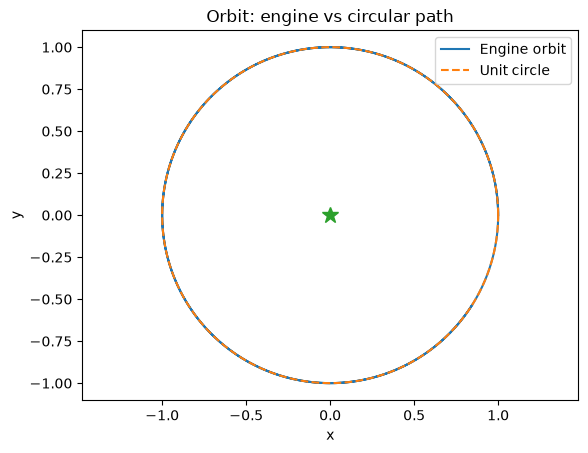

Largest radius deviation: 1.2499921749231646e-05
Maximum relative energy change: 1.5624459191732054e-10
Maximum relative angular momentum change: 1.734723475976807e-15


In [18]:
w = World(VelocityVerlet())
w.add_body(Body(1.0, [0, 0], [0, 0], fixed=True))
w.add_body(Body(0.001, [1, 0], [0, 1]))
w.add_force(NewtonGravity(G=1.0))
w.record('x', lambda W: W.bodies[1].r[0])
w.record('y', lambda W: W.bodies[1].r[1])
w.record('energy', lambda W: W.total_energy())
w.record('L', lambda W: W.bodies[1].m*(W.bodies[1].r[0]*W.bodies[1].v[1] - W.bodies[1].r[1]*W.bodies[1].v[0]))
h = w.run(0.005, 12)
theta = np.linspace(0, 2*np.pi, 300)
plt.plot(h['x'], h['y'], label='Engine orbit')
plt.plot(np.cos(theta), np.sin(theta), '--', label='Unit circle')
plt.plot(0, 0, '*', markersize=12)
plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.title('Orbit: engine vs circular path')
plt.legend(); plt.show()
print('Largest radius deviation:', np.max(np.abs(np.sqrt(h['x']**2+h['y']**2)-1)))
print('Maximum relative energy change:', np.max(np.abs(h['energy']-h['energy'][0]))/abs(h['energy'][0]))
print('Maximum relative angular momentum change:', np.max(np.abs(h['L']-h['L'][0]))/abs(h['L'][0]))


Confirmation Resquested: The orbit remains close to circular, with small changes in total energy and angular momentum. The planet is slightly attracted toward the fixed star; the finite mass ratio makes the exact circular speed slightly different from 1, explaining a small mismatch. This matches the original lab. The small results for the largest radius deviation, and the max energy change and angular momentum change show these stayed relatively consistant throughout the simulation.

Part C: Original multi-body scene 

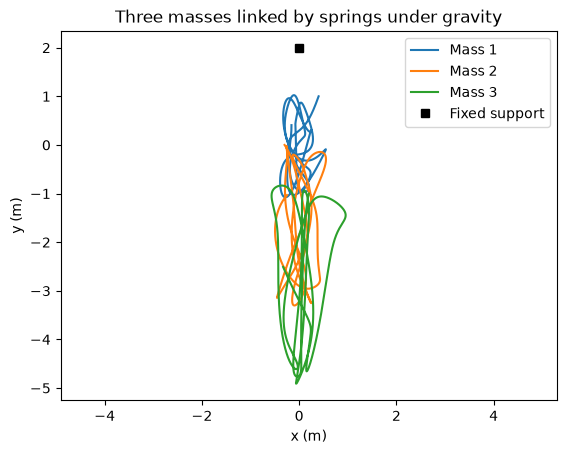

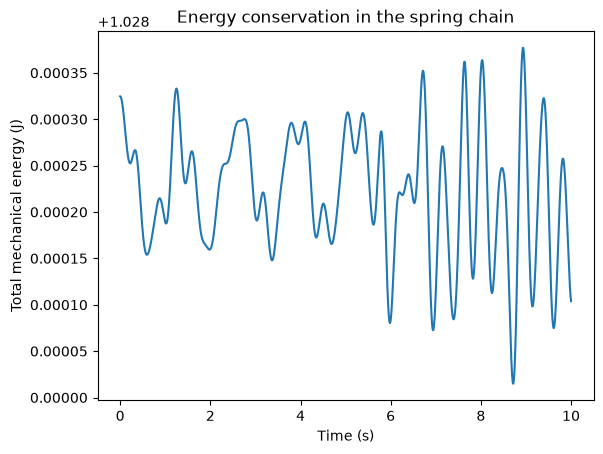

Maximum mechanical energy change (J): 0.0003097456073031246
Relative energy change: 0.0003012138316996083


In [19]:
w = World(VelocityVerlet())
w.add_body(Body(1, [0, 2], [0, 0], fixed=True))
w.add_body(Body(1, [0.4, 1], [0, 0]))
w.add_body(Body(1, [-0.3, 0], [0, 0]))
w.add_body(Body(1, [0.2, -1], [0, 0]))
w.add_force(Gravity(9.81))
w.add_force(Spring(0, 1, k=30, L0=1))
w.add_force(Spring(1, 2, k=30, L0=1))
w.add_force(Spring(2, 3, k=30, L0=1))
w.record('time', lambda W: W.time)
w.record('energy', lambda W: W.total_energy())
for i in range(1, 4):
    w.record(f'x{i}', lambda W, i=i: W.bodies[i].r[0])
    w.record(f'y{i}', lambda W, i=i: W.bodies[i].r[1])
h = w.run(0.002, 10)
for i in range(1, 4):
    plt.plot(h[f'x{i}'], h[f'y{i}'], label=f'Mass {i}')
plt.plot(0, 2, 'ks', label='Fixed support')
plt.xlabel('x (m)'); plt.ylabel('y (m)'); plt.title('Three masses linked by springs under gravity')
plt.axis('equal'); plt.legend(); plt.show()
plt.plot(h['time'], h['energy'])
plt.xlabel('Time (s)'); plt.ylabel('Total mechanical energy (J)')
plt.title('Energy conservation in the spring chain'); plt.show()
print('Maximum mechanical energy change (J):', np.max(np.abs(h['energy']-h['energy'][0])))
print('Relative energy change:', np.max(np.abs(h['energy']-h['energy'][0]))/abs(h['energy'][0]))


The position graph at first seems convuluted and does not immediately give obvious information regarding the system. The fixed support doesn't move which is very important. All of the masses move up and down on the y axis which is expected because they are oscillating (springs). Also, their positions are not perfect oscillations which would be suspicious since they are supposed to affect eachother. Also, the heavier mass moves farther down which makes since because weight is m*g. The three masses move together because the spring forces depend on the distance between neighboring masses. Gravity pulls each moving mass down while spring forces oppose stretching and compression. The trajectories are coupled rather than three separate single-mass oscillations. The nearly constant total mechanical energy indicates that the simulation is behaving as I would expect. The total ME does vary but not as much as the graph implies because the y axis scale is small.  Since there is not drag, energy goes back and forth between kinetic energy, spring potential energy, and gravitational potential energy. Momentum is not expected to be constant because the fixed support exerts an external force.

Bonus:

In [20]:

#Compare Euler-Cromer and Velocity Verlet

def test_orbit(integrator):
    world = World(integrator)

    # Central mass and orbiting body
    sun = Body(1.0, [0, 0], [0, 0], fixed=True)
    planet = Body(0.01, [1, 0], [0, 1])
    world.add_body(sun)
    world.add_body(planet)
    world.add_force(NewtonGravity(G=1.0))

    # Record position and energy
    world.record("position", lambda w: w.bodies[1].r.copy())
    world.record("energy", lambda w: w.total_energy())
    world.record("time", lambda w: w.time)
    return world.run(dt=0.08, t_end=80*np.pi)


# Run both 
euler = test_orbit(EulerCromer())
verlet = test_orbit(VelocityVerlet())


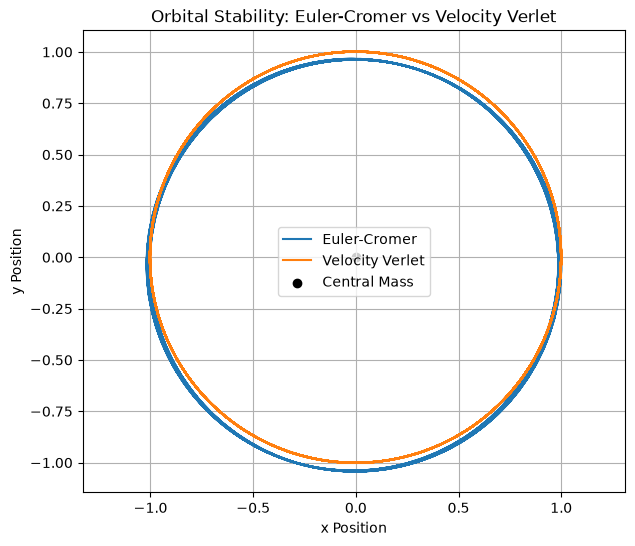

In [21]:
#COmpare/plot both trajectories

plt.figure(figsize=(7, 6))
#plot euler
plt.plot(euler["position"][:, 0],
         euler["position"][:, 1],
         label="Euler-Cromer")
#plot verlet
plt.plot(verlet["position"][:, 0],
         verlet["position"][:, 1],
         label="Velocity Verlet")

plt.scatter(0, 0, color="black", label="Central Mass")
plt.xlabel("x Position")
plt.ylabel("y Position")
plt.title("Orbital Stability: Euler-Cromer vs Velocity Verlet")
plt.axis("equal")
plt.legend()
plt.grid(True)
plt.show()


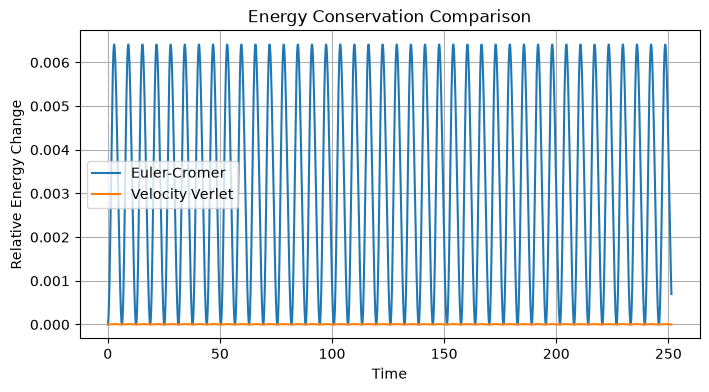

Maximum relative energy change:
Euler-Cromer: 0.0064099514397548615
Velocity Verlet: 1.0142690099780582e-05


In [22]:
#Compare energy conservation:

euler_error = (euler["energy"] - euler["energy"][0]) / abs(euler["energy"][0])
verlet_error = (verlet["energy"] - verlet["energy"][0]) / abs(verlet["energy"][0])

plt.figure(figsize=(8, 4))

plt.plot(euler["time"], euler_error, label="Euler-Cromer")
plt.plot(verlet["time"], verlet_error, label="Velocity Verlet")

plt.xlabel("Time")
plt.ylabel("Relative Energy Change")
plt.title("Energy Conservation Comparison")
plt.legend()
plt.grid(True)
plt.show()

print("Maximum relative energy change:")
print("Euler-Cromer:", np.max(np.abs(euler_error)))
print("Velocity Verlet:", np.max(np.abs(verlet_error)))


I compared the integrator methods of euler-cromer and velocity verlet using the same inital conditions for their orbits. They are both bounded motions but velocity verlet showed a smaller variation in total mechanical energy. This is shown by how euler and verlet when plotted on the same graph ( so same axis) the energy change for verlet appears as a flat horizontal line whereas for euler cromer it oscillates. The differences between these two methods is simple (once explained), but euler cromer updates velocity before position (different than euler) wheras velocity verlet uses acceleration infor to update the position and velocity. This is why verlet is able to maintain as seen on the position graph the expected behavior a lot more consistant over time. This comparison shows how easy it is to change and integrator when you use this format of an energine and how changing the intergrator can help improve numerical accuracy without changing the main body of the problem.